# 05 · Final evaluation on the unseen set (no retraining)

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Wrote and ran all code: loader and schema check for the evaluation file, feature building with the same functions as 04, prediction with the frozen model, metrics, CSV output.
- Added a demo mode: without the evaluation file, it runs the test-period model on 1 Jun – 15 Jul 2023 and reproduces the numbers from notebook 04.

**Not done by Claude**
- No interpretation of any result and no written findings. Every `_Team notes:_` cell is left empty for the team.
- Cluster names or labels in words: none are given in the notebook.
- The team's own files (`data-cleanup.ipynb`, `Scratchpad.ipynb`, `FINDINGS.md`) were not edited.
- Never run on the real evaluation set (not released yet).
- The loader assumes the same columns as `stations_status.csv`. A different format needs an adapter.
- No retraining, on purpose.

_Team notes:_

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import bikeshare_common as bc

bc.set_style()
pd.set_option("display.width", 200)

# path to the released evaluation file (same columns as stations_status.csv)
EVAL_PATH = bc.DATA_DIR / "evaluation" / "stations_status_eval.csv"
# without the file, run the identical pipeline on our own held-out test period with the model that never saw it
DEMO = not EVAL_PATH.exists()
MODEL_PATH = bc.MODEL_DIR / ("availability_hgb_testperiod.joblib" if DEMO else "availability_hgb_final.joblib")
print("DEMO mode" if DEMO else "EVALUATION mode", "| model:", MODEL_PATH.name)

DEMO mode | model: availability_hgb_testperiod.joblib


In [2]:
bundle = joblib.load(MODEL_PATH)
model, FEATS = bundle["model"], bundle["features"]
{k: v for k, v in bundle.items() if k in ["trained_until", "train_rows", "params"]}

{'params': {'loss': 'squared_error',
  'learning_rate': 0.1,
  'max_leaf_nodes': 31,
  'min_samples_leaf': 200},
 'trained_until': '2023-06-01 00:00:00',
 'train_rows': 10101721}

## 1. Load and check the evaluation data

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Schema check; training history prepended so lags exist at the start of the window; weather fetched for the evaluation range into a separate cache.

**Not done by Claude**
- Untested case: if the evaluation period starts more than 7 days after 15 Jul 2023, the first hours have no valid history (lags NaN or rows invalid).

In [3]:
history = pd.read_csv(bc.DATA_DIR / "stations_status.csv")
stations = pd.read_csv(bc.DATA_DIR / "stations.csv")
cities = pd.read_csv(bc.DATA_DIR / "cities.csv")
if DEMO:
    cut = pd.Timestamp(bundle["trained_until"]).timestamp()
    ev_raw = history[history.time >= cut].copy()
    history = history[history.time < cut]
else:
    ev_raw = pd.read_csv(EVAL_PATH)

expected = ["station_id", "time", "bikes", "booked_bikes", "bikes_available_to_rent", "free_racks", "free_special_racks", "maintenance"]
missing = [c for c in expected if c not in ev_raw.columns]
assert not missing, f"evaluation file is missing columns: {missing}"
if not np.issubdtype(ev_raw.time.dtype, np.number):
    ev_raw["time"] = pd.to_datetime(ev_raw.time, utc=True).astype("int64") // 10**9
ev_raw["maintenance"] = ev_raw.maintenance.astype(str).str.lower().isin(["true", "1", "t"])
eval_start = pd.to_datetime(ev_raw.time.min(), unit="s")
eval_end = pd.to_datetime(ev_raw.time.max(), unit="s")
print(f"{len(ev_raw):,} records, {ev_raw.station_id.nunique()} stations, {eval_start} → {eval_end}")
print("stations unseen in training:", (~ev_raw.station_id.isin(history.station_id)).sum(), "records")

745,127 records, 2375 stations, 2023-06-01 00:00:01 → 2023-07-15 21:59:01
stations unseen in training: 2638 records


In [4]:
# prepend training history so lags / rolling windows exist at the start of the evaluation window
full = pd.concat([history[history.station_id.isin(ev_raw.station_id)], ev_raw[expected]], ignore_index=True)
full = full.drop_duplicates(["station_id", "time"], keep="last")

need = cities[cities.id.isin(stations.loc[stations.id.isin(ev_raw.station_id), "city_id"])]
wl = bc.weather_lookup(bc.fetch_weather(need, start=str((eval_start - pd.Timedelta(days=8)).date()),
                                        end=str((eval_end + pd.Timedelta(days=1)).date()),
                                        cache=bc.EXTERNAL_DIR / ("weather_demo.csv" if DEMO else "weather_eval.csv")))

d = bc.build_supervised(full, stations, cities, bundle["capacity"], bundle["profile"], bundle["clusters"], wl,
                        start=eval_start.floor("h"))
print(f"{len(d):,} evaluation station-hours")

2,116,666 evaluation station-hours


## 2. Predict with the frozen model

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Predictions = current value + predicted change, clipped at 0; rounded variant; persistence for comparison; empty-station precision/recall; MAE by hour.

**Not done by Claude**
- The prediction line assumes a change-predicting model (squared or absolute loss), not a Poisson model.

In [5]:
d["pred"] = (d.bikes_available_to_rent + model.predict(d[FEATS])).clip(lower=0)
d["pred_round"] = d.pred.round()
d["persist"] = d.bikes_available_to_rent


def metrics(y, p):
    return {"MAE": np.mean(np.abs(y - p)), "RMSE": np.sqrt(np.mean((y - p) ** 2))}


res = pd.DataFrame({
    "persistence": metrics(d.target, d.persist),
    "model": metrics(d.target, d.pred),
    "model (rounded)": metrics(d.target, d.pred_round),
}).T
res["MAE skill vs persistence"] = 1 - res.MAE / res.loc["persistence", "MAE"]
res.round(4)

,MAE,RMSE,MAE skill vs persistence
persistence,0.2120,0.7138,0.0000
model,0.2564,0.6748,-0.2095
model (rounded),0.2170,0.6844,-0.0238


In [6]:
moved = d.target != d.bikes_available_to_rent
pd.DataFrame({
    "hours with a change": {**metrics(d.target[moved], d.pred[moved]), "persistence MAE": metrics(d.target[moved], d.persist[moved])["MAE"], "share": moved.mean()},
    "hours without change": {**metrics(d.target[~moved], d.pred[~moved]), "persistence MAE": 0.0, "share": (~moved).mean()},
}).T.round(4)

,MAE,RMSE,persistence MAE,share
hours with a change,1.4031,1.7647,1.5382,0.1378
hours without change,0.0731,0.1742,0.0000,0.8622


In [7]:
emp_true = d.target == 0
emp_pred = d.pred < 0.5
tp = (emp_true & emp_pred).sum()
pd.Series({"precision (empty in 1h)": tp / emp_pred.sum(), "recall (empty in 1h)": tp / emp_true.sum(),
           "persistence precision": (emp_true & (d.persist == 0)).sum() / (d.persist == 0).sum(),
           "persistence recall": (emp_true & (d.persist == 0)).sum() / emp_true.sum()}).round(4)

precision (empty in 1h)    0.9405
recall (empty in 1h)       0.8867
persistence precision      0.9216
persistence recall         0.9220
dtype: float64

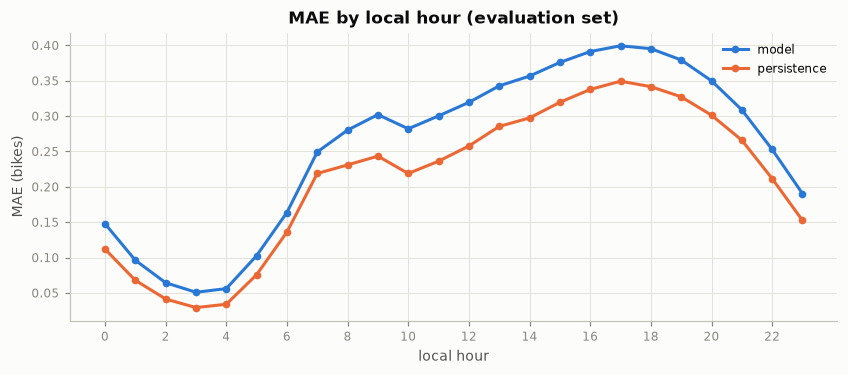

In [8]:
by_hour = d.assign(ae=(d.target - d.pred).abs(), ae_p=(d.target - d.persist).abs()).groupby("hour")[["ae", "ae_p"]].mean()
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(by_hour.index, by_hour.ae, label="model", marker="o", ms=4)
ax.plot(by_hour.index, by_hour.ae_p, label="persistence", marker="o", ms=4)
ax.set(title="MAE by local hour (evaluation set)", xlabel="local hour", ylabel="MAE (bikes)", xticks=range(0, 24, 2))
ax.legend()
plt.show()

## 3. Comparison with the preliminary evaluation (notebook 04)

**[AI provenance: written by Claude, not by the team]**

**Done by Claude**
- Side-by-side with `metrics.json` from 04; predictions written to `models/predictions_{demo|eval}.csv`.

In [9]:
prelim = json.loads((bc.MODEL_DIR / "metrics.json").read_text())
cmp = pd.DataFrame({"preliminary test (04)": prelim["test"], "this run": {"MAE": res.loc["model", "MAE"], "RMSE": res.loc["model", "RMSE"],
                    "persistence_MAE": res.loc["persistence", "MAE"], "persistence_RMSE": res.loc["persistence", "RMSE"],
                    "rows": len(d)}}).T
cmp.round(4)

,MAE,RMSE,persistence_MAE,persistence_RMSE,rows
preliminary test (04),0.2564,0.6748,0.212,0.7138,2116666.0
this run,0.2564,0.6748,0.212,0.7138,2116666.0


In [10]:
out = d[["station_id", "utc", "bikes_available_to_rent", "target", "pred", "pred_round"]].rename(
    columns={"utc": "time_utc", "bikes_available_to_rent": "available_now", "target": "available_in_1h"})
out_path = bc.MODEL_DIR / ("predictions_demo.csv" if DEMO else "predictions_eval.csv")
out.to_csv(out_path, index=False)
out_path.name, out.shape

('predictions_demo.csv', (2116666, 6))